# Olist Sao Paulo 2017: Required Cluster Feature Analysis

This analysis follows `documents/cluster_feature_analysis_req.md` exactly. The original CSV has 52 weekly observations and 9,368 columns: `woy` is metadata and the remaining 9,367 product columns are the feature space.

No transposition or derived features are introduced. The three required pre-geometry screening gates are applied to the original product columns. Geometry profiling and clustering are performed on all surviving features. The sample-to-feature ratio is reported only as a reliability diagnostic and is not used to drop columns.

In [1]:
from pathlib import Path
import pandas as pd

from cluster_profiler import ClusterGeometryProfiler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "SP_2017_freq_prod_weekly_sales.csv"
raw = pd.read_csv(DATA_PATH)
week = raw["woy"].copy()
X = raw.drop(columns="woy")

print({
    "source_rows": raw.shape[0],
    "source_columns": raw.shape[1],
    "screened_observations": X.shape[0],
    "screened_features": X.shape[1],
    "metadata_columns": ["woy"],
})
display(raw.head())

{'source_rows': 52, 'source_columns': 9368, 'screened_observations': 52, 'screened_features': 9367, 'metadata_columns': ['woy']}


,woy,00088930e925c41fd95ebfe695fd2655,0009406fd7479715e4bef61dd91f2462,00126f27c813603687e6ce486d909d01,001795ec6f1b187d37335e1c4704762e,001b72dfd63e9833e8c02742adf472e3,00210e41887c2a8ef9f791ebc780cc36,0021a87d4997a48b6cef1665602be0f5,00250175f79f584c14ab5cecd80553cd,0030026a6ddb3b2d1d4bc225b4b4c4da,...,ffbceea72c6f921df4bb547275b9ca14,ffbe3df3856b1fef3fee8f1264105a89,ffc0b406806006602c5853b00ab5f7fd,ffc48c754b5bd736e2887e279d1dec72,ffc9d90bae2127e6a6ce6d6654267ebd,ffce5ed9e0bcc2e46796b988cdac733b,ffd4bf4306745865e5692f69bd237893,ffe8083298f95571b4a66bfbc1c05524,fff0a542c3c62682f23305214eaeaa24,fff9553ac224cec9d15d49f5a263411f
0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
profiler = ClusterGeometryProfiler(random_state=42).fit_audit(
    X,
    invariance="none",
    feature_names=X.columns.tolist(),
)
feature_accounting = [
    {
        "step": "source_csv_schema",
        "input_features": int(raw.shape[1]),
        "output_features": int(X.shape[1]),
        "dropped_features": 1,
        "action": "excluded_metadata",
        "detail": "woy is week metadata, not a product feature",
    },
    {
        "step": "nonparametric_feature_selector",
        "input_features": int(X.shape[1]),
        "output_features": int(profiler.to_report_dict()["executive_summary"]["pruned_dimensions"]),
        "dropped_features": int(profiler.to_report_dict()["executive_summary"]["dropped_dimensions"]),
        "action": "screened",
        "detail": "Three required sequential gates applied to original product columns; no N/D cap",
    },
    {
        "step": "geometry_reduction",
        "input_features": int(profiler.to_report_dict()["executive_summary"]["pruned_dimensions"]),
        "output_features": int(profiler.to_report_dict()["executive_summary"]["reduced_dimensions"]),
        "dropped_features": 0,
        "action": "embedded",
        "detail": "Geometry-specific coordinate reduction; this is not feature screening",
    },
]
profiler.set_feature_accounting(feature_accounting)

report_before_clustering = profiler.to_report_dict()
screening_stages = pd.DataFrame(
    report_before_clustering["executive_summary"]["screening_stages"]
)
display(screening_stages)
assert screening_stages.iloc[:-1]["output_dimensions"].tolist() == screening_stages.iloc[1:]["input_dimensions"].tolist()
display(pd.DataFrame(feature_accounting))
display(pd.DataFrame([report_before_clustering["executive_summary"]]).T.rename(columns={0: "value"}))
display(pd.DataFrame(report_before_clustering["dropped_features_report"]).value_counts("gate").rename("dropped").to_frame())
display(pd.DataFrame(report_before_clustering["dropped_features_report"]).head(20))

,stage,gate,input_dimensions,output_dimensions,dropped_dimensions,dropped_percentage_of_input
0,1,1_sparsity,9367,2720,6647,70.961887
1,2,2_zero_spread,2720,1270,1450,53.308824
2,3,3_spearman_redundancy,1270,870,400,31.496063


,step,input_features,output_features,dropped_features,action,detail
0,source_csv_schema,9368,9367,1,excluded_metadata,"woy is week metadata, not a product feature"
1,nonparametric_feature_selector,9367,870,8497,screened,Three required sequential gates applied to ori...
2,geometry_reduction,870,7,0,embedded,Geometry-specific coordinate reduction; this i...


,value
input_dimensions,9367
pruned_dimensions,870
reduced_dimensions,7
dropped_dimensions,8497
profiler_pruning_percentage,90.712074
pruning_gate_counts,"{'1_sparsity': 6647, '2_zero_spread': 1450, '3..."
screening_stages,"[{'stage': 1, 'gate': '1_sparsity', 'input_dim..."
screened_dimensions,870
domain_invariance,none
diagnosed_geometry,NON-LINEAR MANIFOLD


,dropped
gate,
1_sparsity,6647
2_zero_spread,1450
3_spearman_redundancy,400


,feature_name,gate,statistic_name,value,threshold,retained_proxy,rationale
0,00088930e925c41fd95ebfe695fd2655,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...
1,0009406fd7479715e4bef61dd91f2462,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...
2,00126f27c813603687e6ce486d909d01,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...
3,0021a87d4997a48b6cef1665602be0f5,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...
4,0030026a6ddb3b2d1d4bc225b4b4c4da,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...
5,0036bb031e69d915cd384d1b3838b5d3,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...
6,003c0b8f6580c850bd2e32044d2ac307,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...
7,005030ef108f58b46b78116f754d8d38,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...
8,00636f9286f69c9f1bdabe76e670fb50,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...
9,00738f5a17ec4450e88915357b085c1e,1_sparsity,mode_frequency,0.980769,<= 0.98,NaN,The dominant value covers nearly all observati...


## Required testing strategy

Feature removal is pre-clustering and label-free. Gate 1 removes degenerate/hyper-sparse columns using mode frequency, unique count, and normalized discrete entropy. Gate 2 removes zero-IQR and zero-MAD columns except valid binary flags. Gate 3 removes feature pairs with absolute Spearman rank correlation above 0.95 and retains the higher-entropy proxy. The sample-to-feature ratio is reported after screening as a reliability diagnostic; it does not remove features.

Kruskal-Wallis epsilon squared, mutual information with cluster labels, and dispersion reduction are computed only after clustering and rank the retained features; they do not remove input columns.

In [3]:
analysis = profiler.analyze_clusters(X, n_clusters=4)
cluster_assignments = pd.DataFrame({
    "week_of_year": week,
    "cluster": analysis.labels,
})
display(cluster_assignments.groupby("cluster").agg(
    weeks=("week_of_year", "size"),
    first_week=("week_of_year", "min"),
    last_week=("week_of_year", "max"),
))
profile = analysis.report_frame("retained_features_profile")
display(profile[[
    "feature_name",
    "normalized_entropy",
    "epsilon_squared",
    "cluster_mutual_information",
    "dispersion_reduction",
]])
display(pd.DataFrame(analysis.to_report_dict()["geometry_diagnostics"], index=[0]).T.rename(columns={0: "value"}))

,weeks,first_week,last_week
cluster,,,
0,23,1,52
1,12,8,46
2,9,14,43
3,8,18,31


,feature_name,normalized_entropy,epsilon_squared,cluster_mutual_information,dispersion_reduction
0,7ca5f56188492e30c50ba64de188aae7,0.391244,0.360532,0.157162,0.000000
1,c6dd917a0be2a704582055949915ab32,0.656866,0.334813,0.170811,0.000000
2,c6ea63369936552872ae890c82175b4b,0.476393,0.322166,0.214827,0.000000
3,007c63ae4b346920756b5adcad8095de,0.318215,0.295281,0.082391,0.000000
4,99a4788cb24856965c36a24e339b6058,0.888401,0.233853,0.129110,0.081531
...,...,...,...,...,...
865,fd28b464cf1660a67606f7b48c8c38c6,0.318215,0.000000,0.016910,1.000000
866,fde4e97b75bd817d8c4aef8de39ed4d9,0.235193,0.000000,0.000000,1.000000
867,fe220782f267bca8c056308cba6c8807,0.235193,0.000000,0.000000,1.000000
868,fe95eb948375116da759c8ef60295001,0.318215,0.000000,0.024240,1.000000


,value
n_to_d_ratio,5.977011e-02
condition_number,4.915869e+13
max_abs_skewness,4.943767e+00
max_excess_kurtosis,2.396988e+01
max_gaussian_mi_gap_nats,1.404573e-01
max_whitened_sq_corr,9.188479e-01
global_participation_ratio,4.400000e+01
local_intrinsic_dimension,5.370641e+00
geodesic_euclidean_p90_ratio,1.443501e+00
convex_vs_connectivity_ari,-5.989796e-02


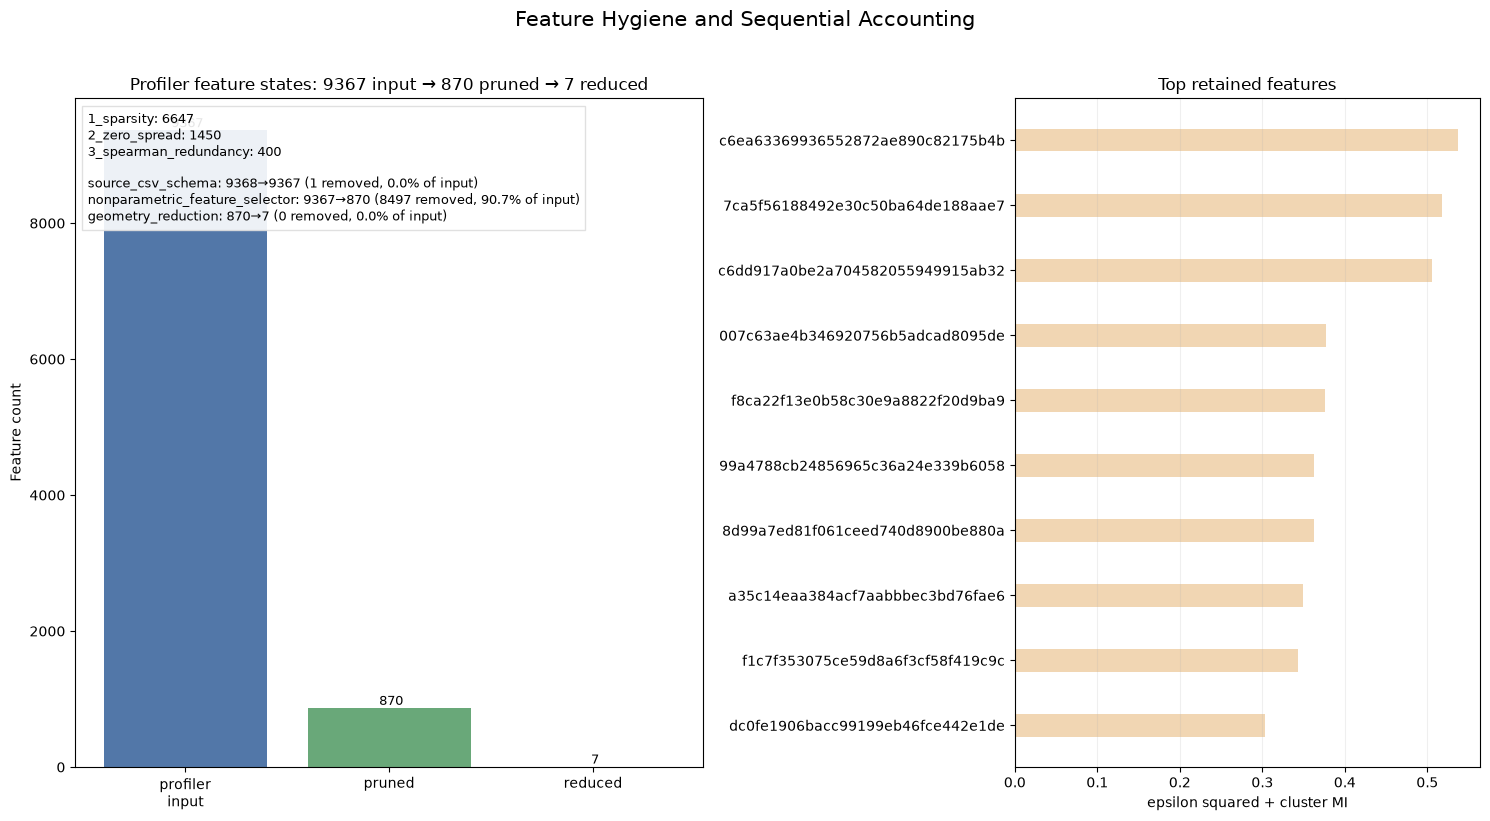

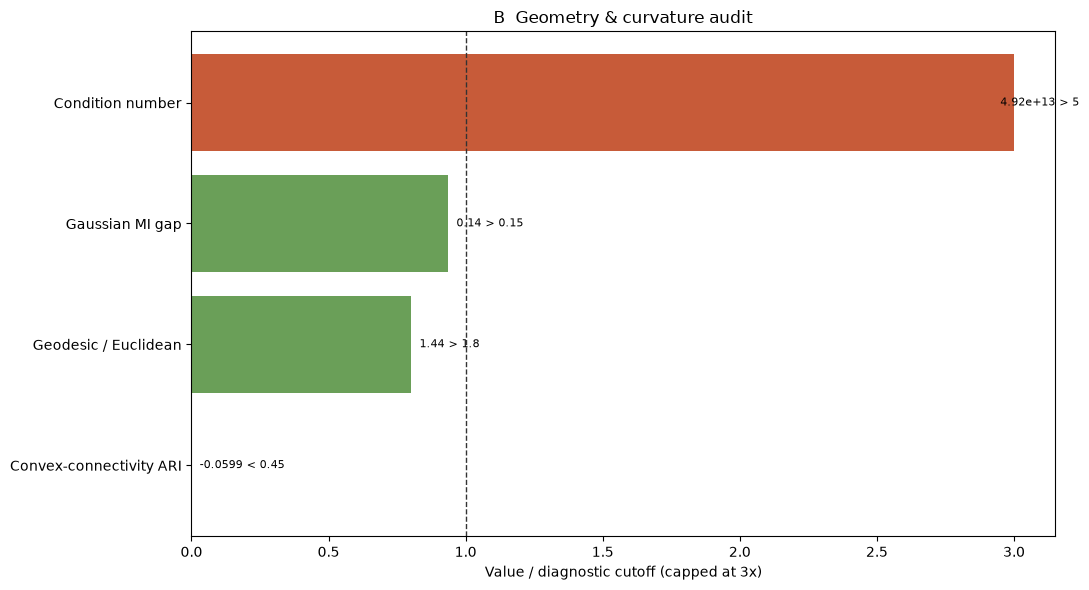

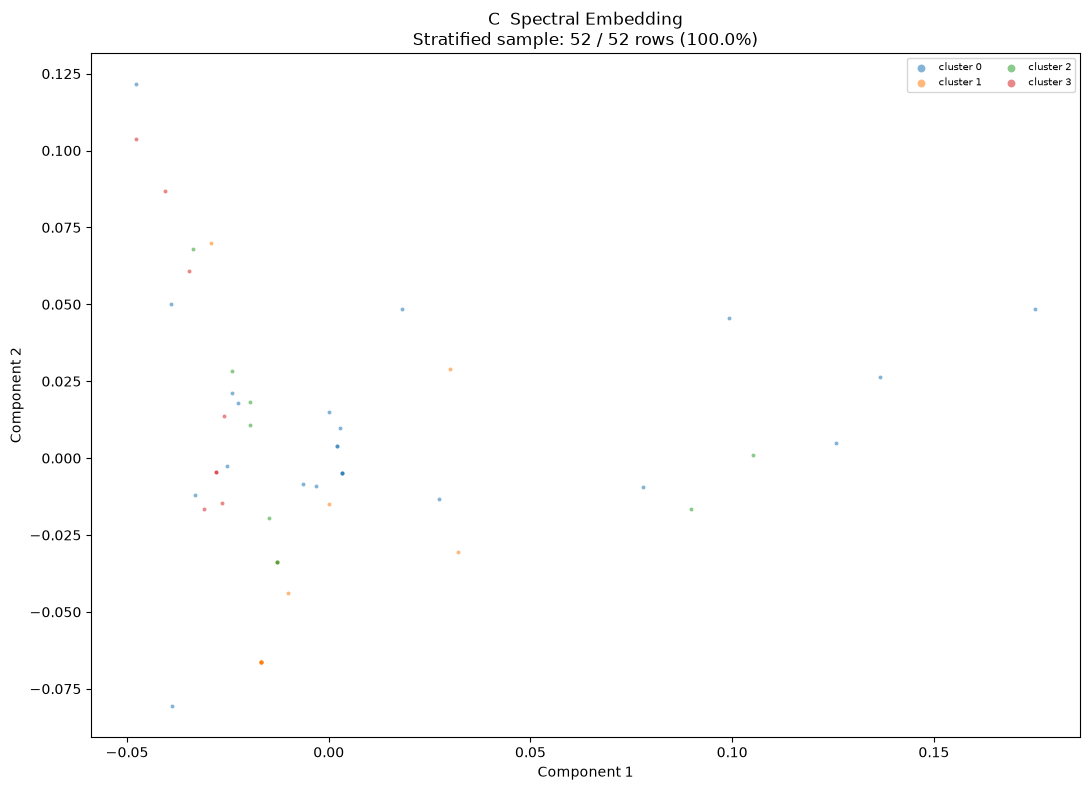

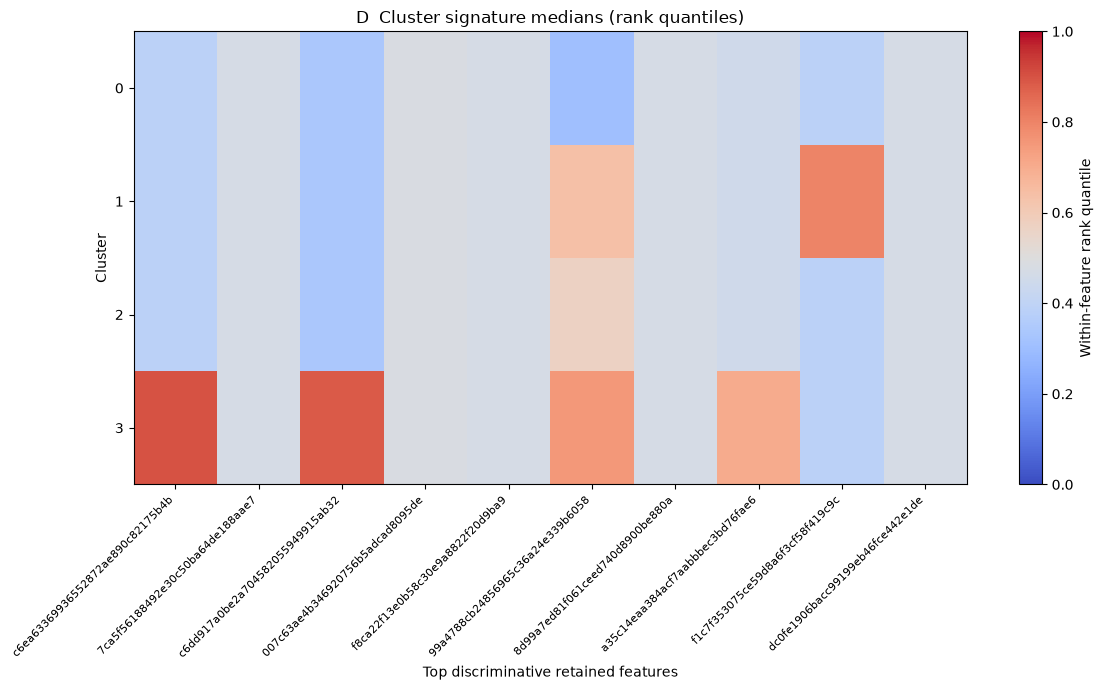

,value
method,Spectral Embedding
fitted_sample_count,52
rendered_sample_count,52
total_rows,52
sampling_fraction,1.0
output_paths,[/home/rajiv/programming/cluster_feature_analy...


In [4]:
FIGURE_DIR = ROOT / "output"
figures = analysis.create_summary_figure(X, output_path=FIGURE_DIR)
for figure in figures:
    display(figure)
display(pd.DataFrame([analysis.visualization_metadata()]).T.rename(columns={0: "value"}))

In [5]:
DROP_REPORT_PATH = ROOT / "data" / "SP_2017_dropped_features.csv"
FILTERED_PATH = ROOT / "data" / "SP_2017_filtered_original_features.csv"
REPORT_PATH = ROOT / "data" / "SP_2017_cluster_feature_report.json"
ASSIGNMENTS_PATH = ROOT / "data" / "SP_2017_week_cluster_assignments.csv"

analysis.export_drop_report(DROP_REPORT_PATH)
analysis.export_filtered_dataset(X, FILTERED_PATH, include_cluster=True)
cluster_assignments.to_csv(ASSIGNMENTS_PATH, index=False)
REPORT_PATH.write_text(analysis.to_json(), encoding="utf-8")

final_report = analysis.to_report_dict()
print("Source columns -> screened features -> pruned -> reduced:",
      final_report["executive_summary"]["source_dimensions"], "->",
      final_report["executive_summary"]["input_dimensions"], "->",
      final_report["executive_summary"]["pruned_dimensions"], "->",
      final_report["executive_summary"]["reduced_dimensions"])
print("Dropped by gate:", final_report["executive_summary"]["pruning_gate_counts"])
print("Retained original columns:", analysis.retained_feature_names)
print("Exports:", final_report["executive_summary"]["exports"])


Source columns -> screened features -> pruned -> reduced: 9368 -> 9367 -> 870 -> 7
Dropped by gate: {'1_sparsity': 6647, '2_zero_spread': 1450, '3_spearman_redundancy': 400}
Retained original columns: ['007c63ae4b346920756b5adcad8095de', '00baba5b58e274d0332a0c8a0a66f877', '00e32638060f6356e6f00749dc466b5c', '010c79af51e82f60de174b6da6060c0a', '0110573bc9195aa810a4384f189f48f5', '013e6676e0e3529e5909ff54370daddf', '015e04445dedbd5da301ef29cbb03f83', '0176bf7839ab4e611dc01cdc3ef6f4e4', '01ef0716b68c8493434ad32430c24e18', '02475368dfb38934fe55f574024fe1d7', '025249b91a565601dc1b8f47ee7a230e', '02fb2d61da1247bf732360ea76b16240', '03552ec45033c8658713c541f6af9f05', '0364c36f8e845e4d309c0a3accc04b1c', '03bca689857bd64cc5c022221113db7e', '03e931f387c2dd5b006aecdb12515b2e', '0432203d03868bfe5fdbb86fb2148474', '04af9f3af5c6afc4eece909c25330934', '04ea63ab87df726ebf45c0982dd90a1f', '05019bc35fc2ed878c0c0f55346b91c6', '0554df77f3ed2e36e06c60eb65dc357a', '060890b1af8cc031e9dde49cf544f884', '06484